<a href="https://colab.research.google.com/github/dheerajdogra102003-create/LLM_COST/blob/main/LLMcost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```
                     📥 RAW DATASET
                           │
                           ▼
         ┌──────────────────────────────────┐
         │ 📋 Features:                     │
         │    • prompt_tokens (Num)         │
         │    • completion_tokens (Num)     │
         │    • model (Cat)                 │
         │    • task (Cat)                  │
         │    • usd (Target Variable 🎯)    │
         └─────────────────┬────────────────┘
                           │
                           ▼
                ⚙️ DATA PREPROCESSING
                           │
         ┌─────────────────┴─────────────────┐
         ▼                                   ▼
 🔢 [Numerical Features]             🔠 [Categorical Features]
   • prompt_tokens                     • model
   • completion_tokens                 • task
         │                                   │
         │ (Impute NaNs & Scale)             │ (One-Hot Encoding)
         │                                   ▼
         │                       ┌───────────────────────┐
         │                       │  model_gpt-5.4-mini   │
         │                       │  task_baseline...     │
         │                       └───────────┬───────────┘
         │                                   │
         └─────────────────┬─────────────────┘
                           │
                           ▼
                 🧠 LINEAR REGRESSION
                  [ y = XW + b ]
                           │
                           ▼
                   💰 PREDICTED USD
```

In [ ]:
from datasets import load_dataset

ds = load_dataset("mario0369/llm-cost-same-prompt")


In [ ]:
ds

DatasetDict({
    train: Dataset({
        features: ['timestamp', 'task', 'model', 'prompt_tokens', 'completion_tokens', 'cached_prompt_tokens', 'usd', 'latency_ms', 'ok', 'error'],
        num_rows: 2466
    })
})

In [ ]:
import pandas as pd

df = ds['train'].to_pandas()
# df.isna().sum()

,0
timestamp,0
task,0
model,0
prompt_tokens,574
completion_tokens,574
cached_prompt_tokens,0
usd,759
latency_ms,0
ok,0
error,1892


In [ ]:
df = df.drop(columns=['timestamp','cached_prompt_tokens','error','ok','latency_ms'])

df=df.dropna(
    subset=[
        'prompt_tokens',
        'completion_tokens',
        'usd'
    ]
)
df.

<class 'pandas.core.frame.DataFrame'>
Index: 1707 entries, 0 to 2463
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   task               1707 non-null   object 
 1   model              1707 non-null   object 
 2   prompt_tokens      1707 non-null   float64
 3   completion_tokens  1707 non-null   float64
 4   usd                1707 non-null   float64
dtypes: float64(3), object(2)
memory usage: 80.0+ KB


In [ ]:
X=df.drop(columns=["usd"])
y=df['usd']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test=train_test_split(X,y ,random_state=42,test_size=0.2)


In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Using standard encoders with dense output representation
encoder_model = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoder_task = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

model_encoded_train = encoder_model.fit_transform(X_train[['model']])
task_encoded_train= encoder_task.fit_transform(X_train[['task']])


model_encoded_test = encoder_model.transform(X_test[['model']])
task_encoded_test = encoder_task.transform(X_test[['task']])

In [ ]:
X_numerical_train=X_train[['prompt_tokens','completion_tokens']]
X_numerical_test=X_test[['prompt_tokens','completion_tokens',]]

In [ ]:
import numpy as np

# Combine the dense arrays and numerical dataframe using numpy's hstack
# No .toarray() needed here because we set sparse_output=False on the encoders
X_final_train = np.hstack([model_encoded_train,
                    task_encoded_train,
                    X_numerical_train.values])

X_final_test = np.hstack([model_encoded_test,
                    task_encoded_test,
                    X_numerical_test.values
                    ])

In [ ]:
# from sklearn.linear_model import (
#     LinearRegression,
#     Ridge,
#     Lasso,
#     ElasticNet
# )

# from sklearn.tree import DecisionTreeRegressor
# from sklearn.ensemble import (
#     RandomForestRegressor,
#     GradientBoostingRegressor,
#     ExtraTreesRegressor
# )

# from sklearn.metrics import (
#     mean_absolute_error,
#     mean_squared_error,
#     r2_score
# )

# from xgboost import XGBRegressor
# from catboost import CatBoostRegressor

# import numpy as np
# import pandas as pd


# # -----------------------------------
# # Define models
# # -----------------------------------

# models = {

#     "Linear Regression": LinearRegression(),

#     "Ridge": Ridge(),

#     "Lasso": Lasso(),

#     "Elastic Net": ElasticNet(),

#     "Decision Tree": DecisionTreeRegressor(
#         random_state=42
#     ),

#     "Random Forest": RandomForestRegressor(
#         n_estimators=100,
#         random_state=42
#     ),

#     "Gradient Boosting": GradientBoostingRegressor(
#         random_state=42
#     ),

#     "Extra Trees": ExtraTreesRegressor(
#         n_estimators=100,
#         random_state=42
#     ),

#     "XGBoost": XGBRegressor(
#         n_estimators=100,
#         random_state=42,
#         objective="reg:squarederror"
#     ),

#     "CatBoost": CatBoostRegressor(
#         iterations=100,
#         verbose=0,
#         random_state=42
#     )
# }


# # -----------------------------------
# # Train and evaluate
# # -----------------------------------
# results = []
# for name, model in models.items():
#     # Train
#     model.fit(X_final_train, y_train)

#     # Prediction
#     y_pred = model.predict(X_final_test)

#     # Metrics
#     mae = mean_absolute_error(y_test, y_pred)
#     mse = mean_squared_error(y_test, y_pred)
#     rmse = np.sqrt(mse)
#     r2 = r2_score(y_test, y_pred)

#     print(f"Model:{name} | MAE:{mae:.3f} | MSE:{mse:.3f} | RMSE:{rmse:.3f} | R2:{r2:.3f}",end="\n\n")


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# model = LinearRegression()
model=ExtraTreesRegressor(
        n_estimators=100,
        random_state=42
    )

model.fit(X_final_train, y_train)

y_pred=model.predict(X_final_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 6.451099251397338e-05
MSE : 4.427806805438858e-08
RMSE: 0.00021042354443927746
R²  : 0.9987043190577934


In [ ]:
def predict_cost(task, model_name, prompt_tokens, completion_tokens):

    new_input = pd.DataFrame({
        "task": [task],
        "model": [model_name],
        "prompt_tokens": [prompt_tokens],
        "completion_tokens": [completion_tokens]
    })

    model_encoded = encoder_model.transform(
        new_input[["model"]]
    )

    task_encoded = encoder_task.transform(
        new_input[["task"]]
    )

    X_numerical = new_input[
        ["prompt_tokens", "completion_tokens"]
    ]

    X_new = np.hstack([
        model_encoded,
        task_encoded,
        X_numerical.values
    ])

    prediction = model.predict(X_new)

    return prediction[0]



cost = predict_cost(
    "summarize",
    "gpt-5.6-luna",
    5000,
    100
)

print("Predicted USD:", cost)

Predicted USD: 0.004498847999999993


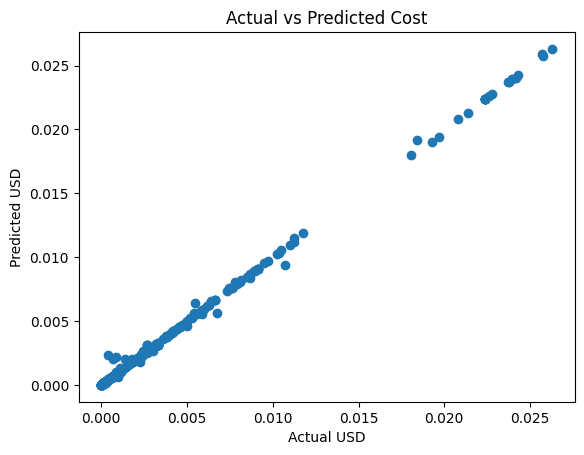

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.xlabel("Actual USD")
plt.ylabel("Predicted USD")
plt.title("Actual vs Predicted Cost")

plt.show()

In [ ]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results["Error"] = results["Actual"] - results["Predicted"]
results["Absolute_Error"] = abs(results["Error"])

results.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

,Actual,Predicted,Error,Absolute_Error
324,0.000375,0.002357,-0.001982,0.001982
16,0.010738,0.009403,0.001335,0.001335
169,0.000684,0.002017,-0.001333,0.001333
121,0.000876,0.002182,-0.001306,0.001306
136,0.006765,0.005605,0.001160,0.001160
51,0.005445,0.006422,-0.000977,0.000977
275,0.018384,0.019149,-0.000765,0.000765
159,0.001410,0.002025,-0.000615,0.000615
248,0.002654,0.003166,-0.000512,0.000512
32,0.002654,0.003166,-0.000512,0.000512


In [ ]:
results = pd.DataFrame({
    "index": y_test.index,
    "Actual": y_test.values,
    "Predicted": y_pred
})

results["Error"] = results["Actual"] - results["Predicted"]
results["Absolute_Error"] = abs(results["Error"])

results = results.sort_values(
    "Absolute_Error",
    ascending=False
)

# Add original information
results = results.merge(
    df[["task", "model", "prompt_tokens", "completion_tokens", "usd"]],
    left_on="index",
    right_index=True,
    suffixes=("", "_original")
)

print(results.head(10))

     index    Actual  Predicted     Error  Absolute_Error             task  \
324    169  0.000375   0.002357 -0.001982        0.001982     short_answer   
16    1369  0.010738   0.009403  0.001335        0.001335        summarize   
169    708  0.000684   0.002017 -0.001333        0.001333        summarize   
121    500  0.000876   0.002182 -0.001306        0.001306        summarize   
136    888  0.006765   0.005605  0.001160        0.001160        summarize   
51    2165  0.005445   0.006422 -0.000977        0.000977        summarize   
275   1563  0.018384   0.019149 -0.000765        0.000765  structured_json   
159   1903  0.001410   0.002025 -0.000615        0.000615     short_answer   
248    796  0.002654   0.003166 -0.000512        0.000512     short_answer   
32     328  0.002654   0.003166 -0.000512        0.000512     short_answer   

                 model  prompt_tokens  completion_tokens       usd  
324  deepseek-v4-flash           26.0              516.0  0.000375  
16 

In [ ]:
results["model"] = df.loc[results["index"], "model"].values

model_comparison = results.groupby("model").agg(
    Actual_Avg=("Actual", "mean"),
    Predicted_Avg=("Predicted", "mean"),
    MAE=("Absolute_Error", "mean")
)

print(model_comparison)

                   Actual_Avg  Predicted_Avg       MAE
model                                                 
GLM5.2               0.000859       0.000863  0.000004
Kimi-K3              0.002684       0.002685  0.000116
claude-fable-5       0.004218       0.004184  0.000093
claude-opus-4-8      0.001706       0.001665  0.000076
claude-opus-5        0.002052       0.002069  0.000021
claude-sonnet-5      0.000614       0.000606  0.000030
deepseek-v4-flash    0.000126       0.000162  0.000047
gemini-3.5-flash     0.004704       0.004691  0.000023
gpt-5.5              0.019858       0.019721  0.000137
gpt-5.6-luna         0.002111       0.002288  0.000182
gpt-5.6-sol          0.014048       0.014076  0.000068
gpt-5.6-terra        0.007692       0.007772  0.000092
grok-4.6             0.005352       0.005318  0.000056


### Visualizing Model Accuracy

Let's plot the actual vs. predicted values and analyze the residuals to inspect where the model is making errors.

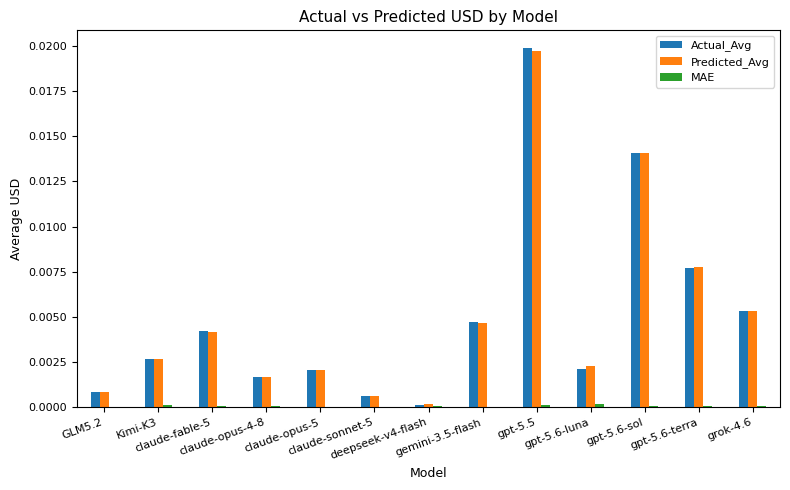

In [ ]:
import matplotlib.pyplot as plt

model_comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Actual vs Predicted USD by Model", fontsize=11)
plt.xlabel("Model", fontsize=9)
plt.ylabel("Average USD", fontsize=9)

plt.xticks(rotation=20, ha="right", fontsize=8)
plt.yticks(fontsize=8)

plt.legend(fontsize=8)
plt.tight_layout()
plt.show()